# 🧑‍💼 Face Recognition & Attendance System
End-to-end demo: **detect → recognise → mark attendance**, using OpenCV YuNet (detection) + SFace (recognition).

**Steps:**
. 1) setup
· 2) register people
· 3) recognise faces
· 4) mark attendance
· 5) webcam
· 6) download results

> Face data is personal biometric data - use only photos of people who gave consent.

## 1. Setup

In [8]:
import cv2
print("OpenCV:", cv2.__version__)

OpenCV: 4.14.0


Write the core engine to `face_engine.py` (same file as in the GitHub repo).

In [9]:
%%writefile face_engine.py
"""Core logic: face detection + recognition + attendance (OpenCV YuNet + SFace).

Used by the Colab notebook, the Streamlit app (app.py) and realtime.py.
No dlib / heavy install needed - only OpenCV (>= 4.5.4), NumPy and Pandas.
"""
import pickle
import urllib.request
from datetime import datetime
from pathlib import Path
from zoneinfo import ZoneInfo

import cv2
import numpy as np
import pandas as pd

TIMEZONE = "Asia/Karachi"          # attendance timestamps (Colab runs in UTC)
MODEL_DIR = Path("models")
DATA_DIR = Path("data")
EMB_FILE = DATA_DIR / "embeddings.pkl"
ATT_FILE = DATA_DIR / "attendance.csv"
COSINE_THRESHOLD = 0.363           # recommended SFace cosine threshold

_ZOO = "https://github.com/opencv/opencv_zoo/raw/main/models"
MODELS = {
    "face_detection_yunet_2023mar.onnx": f"{_ZOO}/face_detection_yunet/face_detection_yunet_2023mar.onnx",
    "face_recognition_sface_2021dec.onnx": f"{_ZOO}/face_recognition_sface/face_recognition_sface_2021dec.onnx",
}
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def download_models():
    """Download the two ONNX models once (YuNet ~0.2 MB, SFace ~37 MB)."""
    MODEL_DIR.mkdir(exist_ok=True)
    for name, url in MODELS.items():
        path = MODEL_DIR / name
        if not path.exists() or path.stat().st_size < 100_000:
            print(f"Downloading {name} ...")
            urllib.request.urlretrieve(url, path)
        if path.stat().st_size < 100_000:
            raise RuntimeError(f"{name} download looks broken - check your internet connection.")


def _now():
    return datetime.now(ZoneInfo(TIMEZONE))


class FaceEngine:
    def __init__(self, score_threshold=0.8, match_threshold=COSINE_THRESHOLD):
        download_models()
        self.detector = cv2.FaceDetectorYN.create(
            str(MODEL_DIR / "face_detection_yunet_2023mar.onnx"), "", (320, 320),
            score_threshold, 0.3, 5000)
        self.recognizer = cv2.FaceRecognizerSF.create(
            str(MODEL_DIR / "face_recognition_sface_2021dec.onnx"), "")
        self.threshold = match_threshold
        self.db = {}                # name -> list of 128-d embeddings
        self.load()

    # ---------- storage ----------
    def load(self):
        if EMB_FILE.exists():
            with open(EMB_FILE, "rb") as f:
                self.db = pickle.load(f)

    def save(self):
        DATA_DIR.mkdir(exist_ok=True)
        with open(EMB_FILE, "wb") as f:
            pickle.dump(self.db, f)

    def people(self):
        return {name: len(embs) for name, embs in self.db.items()}

    def delete(self, name):
        self.db.pop(name, None)
        self.save()

    # ---------- detection / embedding ----------
    def detect(self, bgr):
        h, w = bgr.shape[:2]
        self.detector.setInputSize((w, h))
        _, faces = self.detector.detect(bgr)
        return [] if faces is None else list(faces)

    def embed(self, bgr, face):
        aligned = self.recognizer.alignCrop(bgr, face)
        return self.recognizer.feature(aligned)

    # ---------- registration ----------
    def register(self, name, bgr, save=True):
        """Add the largest face in the image to `name`. Returns True on success."""
        faces = self.detect(bgr)
        if not faces:
            return False
        face = max(faces, key=lambda f: f[2] * f[3])
        self.db.setdefault(name, []).append(self.embed(bgr, face))
        if save:
            self.save()
        return True

    def register_folder(self, root="dataset"):
        """dataset/<Person Name>/*.jpg  ->  {name: images_registered}"""
        counts = {}
        for person in sorted(Path(root).iterdir()):
            if not person.is_dir():
                continue
            ok = 0
            for img_path in person.iterdir():
                if img_path.suffix.lower() in IMG_EXT:
                    img = cv2.imread(str(img_path))
                    if img is not None and self.register(person.name, img, save=False):
                        ok += 1
            counts[person.name] = ok
        self.save()
        return counts

    # ---------- recognition ----------
    def identify(self, emb):
        best_name, best_score = "Unknown", -1.0
        for name, embs in self.db.items():
            for e in embs:
                s = self.recognizer.match(emb, e, cv2.FaceRecognizerSF_FR_COSINE)
                if s > best_score:
                    best_name, best_score = name, s
        if best_score < self.threshold:
            return "Unknown", best_score
        return best_name, best_score

    def recognize(self, bgr):
        results = []
        for f in self.detect(bgr):
            name, score = self.identify(self.embed(bgr, f))
            x, y, w, h = f[:4].astype(int)
            results.append({"name": name, "score": float(score), "box": (x, y, w, h)})
        return results

    @staticmethod
    def annotate(bgr, results):
        out = bgr.copy()
        for r in results:
            x, y, w, h = r["box"]
            color = (0, 200, 0) if r["name"] != "Unknown" else (0, 0, 255)
            cv2.rectangle(out, (x, y), (x + w, y + h), color, 2)
            cv2.putText(out, f'{r["name"]} ({r["score"]:.2f})', (x, max(y - 8, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
        return out


# ---------- attendance ----------
def load_attendance(path=ATT_FILE):
    path = Path(path)
    if path.exists():
        return pd.read_csv(path, dtype=str)
    return pd.DataFrame(columns=["Name", "Date", "Time"])


def mark_attendance(name, path=ATT_FILE):
    """One entry per person per day. Returns True if newly marked."""
    path = Path(path)
    now = _now()
    date, time = now.strftime("%Y-%m-%d"), now.strftime("%H:%M:%S")
    df = load_attendance(path)
    if ((df["Name"] == name) & (df["Date"] == date)).any():
        return False
    df.loc[len(df)] = [name, date, time]
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=False)
    return True

Overwriting face_engine.py


In [10]:
from face_engine import FaceEngine, mark_attendance, load_attendance

engine = FaceEngine()          # downloads the 2 ONNX models on first run
print("Registered people:", engine.people())

Registered people: {'Muhammad Abdullah': 4, 'Muhammad Riyyan': 4}


## 2. Register people
Upload a **`dataset.zip`** with this structure (folder name = person name, 3-5 clear photos each):
```
dataset/
  Muhammad Abdullah/1.jpeg 2.jpeg 3.jpeg 4.jpeg
  Muhammad Riyyan/1.jpeg 2.jpeg 3.jpeg 4.jpeg
```
Zip the *person folders* directly (or a single `dataset` folder containing them).

In [11]:
from google.colab import files
import zipfile, shutil, os

up = files.upload()                      # choose dataset.zip
shutil.rmtree("dataset", ignore_errors=True)
zipfile.ZipFile(next(iter(up))).extractall("dataset")
# if the zip had one top-level 'dataset' folder, step into it
inner = os.path.join("dataset", "dataset")
DATASET = inner if os.path.isdir(inner) else "dataset"
print(os.listdir(DATASET))

Saving Muhammad Abdullah.zip to Muhammad Abdullah (3).zip
Saving Muhammad Riyyan.zip to Muhammad Riyyan (1).zip
['Muhammad Abdullah']


In [22]:
counts = engine.register_folder(DATASET)
print(counts)      # images successfully registered per person (0 = no face found)

{'Muhammad Abdullah': 4}


## 3. Recognise faces in a photo (group photos work too)

Saving Sample.jpeg to Sample.jpeg


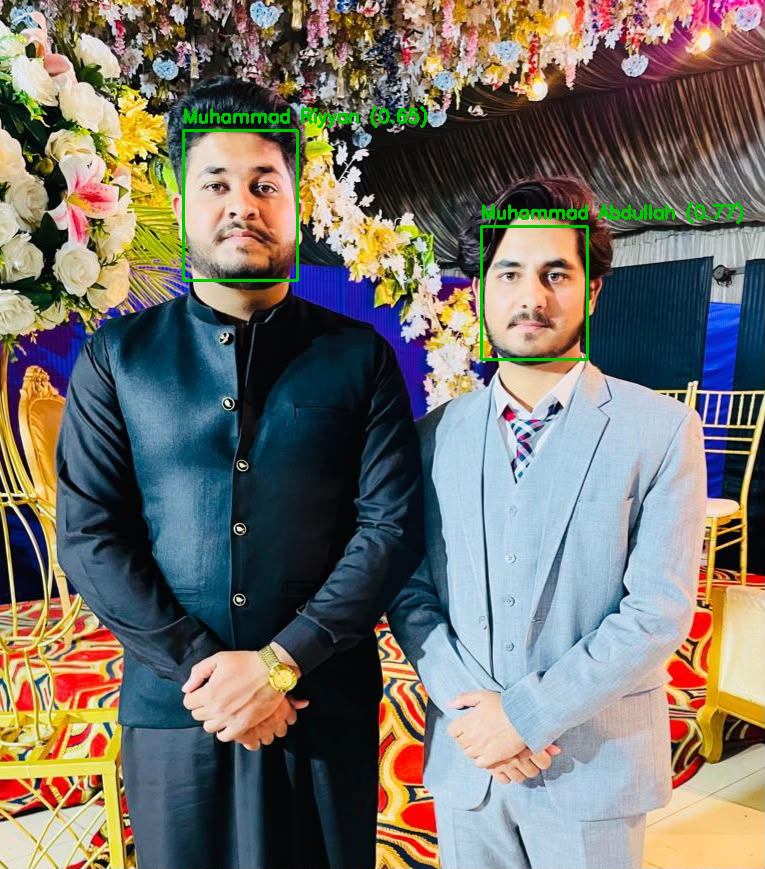

Muhammad Abdullah 0.774
Muhammad Riyyan 0.654


In [14]:
from google.colab.patches import cv2_imshow

up = files.upload()                      # choose a test photo
img = cv2.imread(next(iter(up)))
results = engine.recognize(img)
cv2_imshow(engine.annotate(img, results))
for r in results:
    print(r["name"], round(r["score"], 3))

> Registered people showing as **Unknown**? Lower `engine.threshold` (e.g. 0.30).
> Different people getting confused? Raise it (e.g. 0.42).

## 4. Mark attendance (once per person per day)

In [23]:
for r in results:
    if r["name"] != "Unknown":
        status = "marked present" if mark_attendance(r["name"]) else "already marked today"
        print(f'{r["name"]}: {status}')

load_attendance()

Muhammad Abdullah: already marked today


,Name,Date,Time
0,Muhammad Abdullah,2026-10-15,01:51:44
1,Muhammad Riyyan,2026-10-15,01:51:44


## 5. (Optional) Capture from the Colab webcam

In [16]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def take_photo(filename="photo.jpg", quality=0.8):
    js = Javascript('''
      async function takePhoto(quality) {
        const div = document.createElement('div');
        const capture = document.createElement('button');
        capture.textContent = 'Capture';
        div.appendChild(capture);
        const video = document.createElement('video');
        video.style.display = 'block';
        const stream = await navigator.mediaDevices.getUserMedia({video: true});
        document.body.appendChild(div);
        div.appendChild(video);
        video.srcObject = stream;
        await video.play();
        google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
        await new Promise((resolve) => capture.onclick = resolve);
        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;
        canvas.getContext('2d').drawImage(video, 0, 0);
        stream.getVideoTracks()[0].stop();
        div.remove();
        return canvas.toDataURL('image/jpeg', quality);
      }
    ''')
    display(js)
    data = eval_js('takePhoto({})'.format(quality))
    with open(filename, 'wb') as f:
        f.write(b64decode(data.split(',')[1]))
    return filename

<IPython.core.display.Javascript object>

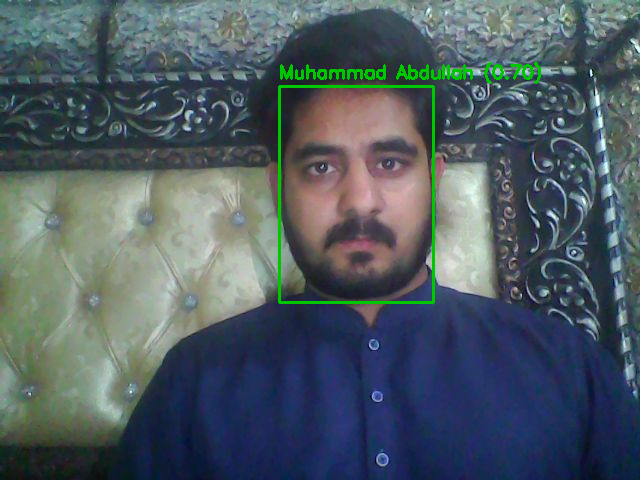

Muhammad Abdullah -> already marked today


In [20]:
img = cv2.imread(take_photo())
results = engine.recognize(img)
cv2_imshow(engine.annotate(img, results))
for r in results:
    if r["name"] != "Unknown":
        print(r["name"], "->", "marked present" if mark_attendance(r["name"]) else "already marked today")

## 6. Download results
`embeddings.pkl` can be copied into the `data/` folder of the Streamlit app so the registered people carry over.

In [24]:
files.download("data/attendance.csv")
files.download("data/embeddings.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Next step
Run the Streamlit UI locally: `streamlit run app.py` (see the GitHub README).